# 30-Day Hospital Readmission (India): ML/DL Comparison, Baseline, Calibration and Design Audit
Version 2 notebook for the merged paper. Adds a prior-only baseline, Brier scores, subgroup rates and a design audit
(effect of keeping in-hospital deaths and of a random vs patient-grouped split). Outputs go to `outputs_v2/`.

## 1. Setup

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
try:
    import xgboost
except ImportError:
    %pip install -q xgboost
IN_COLAB = 'google.colab' in sys.modules
DATA_DIR = "All Data"   # folder containing the 5 CSV files
if IN_COLAB and not os.path.isdir(DATA_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = "/content/drive/MyDrive/All Data"   # <-- change to your Drive path
OUT = "outputs_v2"
os.makedirs("src", exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True); os.makedirs(f"{OUT}/tables", exist_ok=True)
print("Data dir:", DATA_DIR, "->", sorted(os.listdir(DATA_DIR)))

Data dir: All Data -> ['admissions.csv', 'billing.csv', 'diagnoses.csv', 'hospitals.csv', 'patients.csv']


In [2]:
%%writefile src/preprocessing.py
"""Load the five relational tables, merge them and prepare model-ready matrices."""
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
TARGET = "readmitted_30d"
LEAK_COLS = ["readmitted_7d"]  # 7-day outcome is a sub-event of the target


def load_tables(data_dir):
    # keep_default_na=False: the string "None" in insurance_type means uninsured, not missing
    t = {n: pd.read_csv(f"{data_dir}/{n}.csv", keep_default_na=False, na_values=[""])
         for n in ["admissions", "patients", "diagnoses", "billing", "hospitals"]}
    return t


def quality_report(t):
    rep = {}
    for n, d in t.items():
        rep[n] = dict(rows=len(d), cols=d.shape[1], missing=int(d.isna().sum().sum()),
                      duplicates=int(d.duplicated().sum()))
    return rep


def build_dataset(t, drop_expired=True):
    a, p, d, b, h = (t[k].copy() for k in ["admissions", "patients", "diagnoses", "billing", "hospitals"])
    a = a.drop_duplicates("admission_id")
    prim = d[d.diag_rank == 1].drop_duplicates("admission_id")[["admission_id", "diag_category"]]
    ndx = d.groupby("admission_id").size().rename("n_diagnoses").reset_index()
    h = h[["hospital_id", "tier", "beds", "teaching"]].rename(columns={"tier": "hospital_tier"})
    p = p.rename(columns={"state": "patient_state"})
    df = (a.merge(p, on="patient_id", how="left").merge(h, on="hospital_id", how="left")
           .merge(b.drop(columns="bill_id"), on="admission_id", how="left")
           .merge(prim, on="admission_id", how="left").merge(ndx, on="admission_id", how="left"))
    n0 = len(df)
    if drop_expired:  # patients who died cannot be readmitted
        df = df[df.discharge_type != "Expired"]
    df["admit_date"] = pd.to_datetime(df["admit_date"])
    df["admit_year"] = df.admit_date.dt.year
    df["admit_month"] = df.admit_date.dt.month
    df["cost_per_day"] = df.total_cost_inr / df.los_days.clip(lower=1)
    df["oop_share"] = df.out_of_pocket_inr / df.total_cost_inr.clip(lower=1)
    df["teaching"] = df["teaching"].astype(int)
    df["bpl_card"] = df["bpl_card"].astype(int)
    df["diag_category"] = df["diag_category"].fillna("Unknown")
    df["n_diagnoses"] = df["n_diagnoses"].fillna(1)
    df.attrs["dropped_expired"] = n0 - len(df)
    return df.reset_index(drop=True)


ID_COLS = ["admission_id", "patient_id", "hospital_id", "admit_date", "discharge_date"]
CAT_COLS = ["admit_type", "ward_type", "discharge_type", "gender", "patient_state", "insurance_type",
            "hospital_tier", "cost_category", "diag_category"]


def feature_frame(df):
    """One-hot encode categoricals; median-impute numerics. Returns X (DataFrame), y."""
    X = df.drop(columns=ID_COLS + [TARGET] + LEAK_COLS)
    num = [c for c in X.columns if c not in CAT_COLS]
    X[num] = X[num].fillna(X[num].median())
    X[CAT_COLS] = X[CAT_COLS].fillna("Unknown")
    X = pd.get_dummies(X, columns=CAT_COLS, dtype=float)
    return X, df[TARGET].values, num


def split_by_patient(df, seed=SEED, test=0.15, val=0.15):
    """Patient-grouped stratification-free split so one patient never spans two sets."""
    g = df.patient_id.values
    gss = GroupShuffleSplit(n_splits=1, test_size=test, random_state=seed)
    tv, te = next(gss.split(df, groups=g))
    gss2 = GroupShuffleSplit(n_splits=1, test_size=val / (1 - test), random_state=seed)
    tr, va = next(gss2.split(df.iloc[tv], groups=g[tv]))
    return tv[tr], tv[va], te


def scale(X_tr, X_va, X_te, num_cols):
    sc = StandardScaler().fit(X_tr[num_cols])
    out = []
    for X in (X_tr, X_va, X_te):
        Z = X.copy()
        Z[num_cols] = sc.transform(X[num_cols])
        out.append(Z)
    return out

Overwriting src/preprocessing.py


In [3]:
%%writefile src/models.py
"""Model definitions, training and evaluation helpers."""
import time
import numpy as np
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from xgboost import XGBClassifier

SEED = 42


def best_threshold(y, p):
    """Threshold maximising F1 on the validation set."""
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return float(th[np.argmax(f1[:-1])])


def metrics(y, p, thr):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh).ravel()
    return dict(accuracy=accuracy_score(y, yh), precision=precision_score(y, yh, zero_division=0),
                recall=recall_score(y, yh), f1=f1_score(y, yh), roc_auc=roc_auc_score(y, p),
                pr_auc=average_precision_score(y, p), threshold=thr, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
                specificity=tn / (tn + fp))


class MLP(nn.Module):
    def __init__(self, d, hidden=(128, 64, 32), drop=0.3):
        super().__init__()
        layers, prev = [], d
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(drop)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


class TorchMLP:
    def __init__(self, hidden=(128, 64, 32), drop=0.3, lr=1e-3, batch=512, epochs=60, patience=6, seed=SEED):
        self.hidden, self.drop, self.lr, self.batch, self.epochs, self.patience, self.seed = hidden, drop, lr, batch, epochs, patience, seed
        self.history = {"train_loss": [], "val_loss": []}

    def fit(self, X, y, Xv, yv):
        torch.manual_seed(self.seed); np.random.seed(self.seed)
        X, Xv = torch.tensor(np.asarray(X), dtype=torch.float32), torch.tensor(np.asarray(Xv), dtype=torch.float32)
        y, yv = torch.tensor(y, dtype=torch.float32), torch.tensor(yv, dtype=torch.float32)
        self.m = MLP(X.shape[1], self.hidden, self.drop)
        pw = (1 - y.mean()) / y.mean()
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
        opt = torch.optim.Adam(self.m.parameters(), lr=self.lr)
        best, bad, state = 1e9, 0, None
        for ep in range(self.epochs):
            self.m.train(); perm = torch.randperm(len(X)); tl = 0
            for i in range(0, len(X), self.batch):
                idx = perm[i:i + self.batch]
                opt.zero_grad(); l = loss_fn(self.m(X[idx]), y[idx]); l.backward(); opt.step(); tl += l.item() * len(idx)
            self.m.eval()
            with torch.no_grad():
                vl = loss_fn(self.m(Xv), yv).item()
            self.history["train_loss"].append(tl / len(X)); self.history["val_loss"].append(vl)
            if vl < best - 1e-4:
                best, bad, state = vl, 0, {k: v.clone() for k, v in self.m.state_dict().items()}
            else:
                bad += 1
                if bad >= self.patience:
                    break
        self.m.load_state_dict(state); return self

    def predict_proba1(self, X):
        self.m.eval()
        with torch.no_grad():
            return torch.sigmoid(self.m(torch.tensor(np.asarray(X), dtype=torch.float32))).numpy()


def make_sklearn_models(pos_weight):
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=20,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                                 colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric="auc",
                                 n_jobs=-1, random_state=SEED, early_stopping_rounds=30),
    }


def run_all(Xtr, ytr, Xva, yva, Xte, yte, Xtr_s, Xva_s, Xte_s):
    """Train every model; return dict name -> results, plus fitted objects."""
    pw = (1 - ytr.mean()) / ytr.mean()
    res, fitted = {}, {}
    for name, m in make_sklearn_models(pw).items():
        scaled = name == "Logistic Regression"
        A, B, C = (Xtr_s, Xva_s, Xte_s) if scaled else (Xtr, Xva, Xte)
        t0 = time.time()
        if name == "XGBoost":
            m.fit(A, ytr, eval_set=[(B, yva)], verbose=False)
        else:
            m.fit(A, ytr)
        tt = time.time() - t0
        pv = m.predict_proba(B)[:, 1]; thr = best_threshold(yva, pv)
        t1 = time.time(); pt = m.predict_proba(C)[:, 1]; tp = time.time() - t1
        r = metrics(yte, pt, thr); r.update(train_time_s=tt, predict_time_s=tp, val_roc_auc=roc_auc_score(yva, pv))
        res[name], fitted[name] = r, (m, pt)
    t0 = time.time(); mlp = TorchMLP().fit(Xtr_s, ytr, Xva_s, yva); tt = time.time() - t0
    pv = mlp.predict_proba1(Xva_s); thr = best_threshold(yva, pv)
    t1 = time.time(); pt = mlp.predict_proba1(Xte_s); tp = time.time() - t1
    r = metrics(yte, pt, thr); r.update(train_time_s=tt, predict_time_s=tp, val_roc_auc=roc_auc_score(yva, pv),
                                        epochs_run=len(mlp.history["val_loss"]))
    res["MLP (DL)"], fitted["MLP (DL)"] = r, (mlp, pt)
    return res, fitted

Overwriting src/models.py


In [4]:
%%writefile src/visualization.py
"""IEEE-sized figure helpers (single column ~3.5 in, 300 dpi)."""
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "figure.dpi": 150, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .3})
FIG_DIR = "outputs/figures"
COLS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]


def save(fig, name):
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")
    fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")


def flow_diagram(steps, name, ncols=1, w=3.5, h=None, box_w=0.8):
    """Vertical/serpentine flow of labelled boxes joined by arrows."""
    n = len(steps)
    h = h or 0.42 * n + 0.2
    fig, ax = plt.subplots(figsize=(w, h)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, n)
    for i, s in enumerate(steps):
        y = n - i - 0.5
        ax.add_patch(FancyBboxPatch((0.5 - box_w / 2, y - 0.3), box_w, 0.6, boxstyle="round,pad=0.01,rounding_size=0.04",
                                    fc="#EAF0F8", ec="#1F3A5F", lw=0.8))
        ax.text(0.5, y, s, ha="center", va="center", fontsize=7)
        if i < n - 1:
            ax.annotate("", xy=(0.5, y - 0.62), xytext=(0.5, y - 0.3),
                        arrowprops=dict(arrowstyle="-|>", color="#1F3A5F", lw=0.8))
    save(fig, name); return fig


def _box(ax, x, y, w, h, txt, fc="#EAF0F8", fs=6.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.005,rounding_size=0.02",
                                fc=fc, ec="#1F3A5F", lw=0.8))
    ax.text(x, y, txt, ha="center", va="center", fontsize=fs)


def _arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#1F3A5F", lw=0.8))


def architecture(name, info, fname):
    """Conceptual architecture of the best model, using the parameters actually used."""
    fig, ax = plt.subplots(figsize=(3.5, 2.3)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    if name.startswith("MLP"):
        sizes = [info["n_features"]] + list(info["hidden"]) + [1]
        labels = [f"Input\n({sizes[0]})"] + [f"Dense {s}\nReLU+Drop" for s in sizes[1:-1]] + ["Output\n(1, sigmoid)"]
        n = len(labels); xs = np.linspace(0.11, 0.89, n)
        for x, l in zip(xs, labels):
            _box(ax, x, 0.5, 0.16, 0.42, l, fs=6)
        for a, b in zip(xs[:-1], xs[1:]):
            _arrow(ax, a + 0.08, 0.5, b - 0.08, 0.5)
        ax.text(0.5, 0.15, f"Adam, BCE (class-weighted), early stopping", ha="center", fontsize=6.5)
    elif name == "Logistic Regression":
        _box(ax, 0.15, 0.5, 0.26, 0.5, f"Input features\n({info['n_features']}, scaled)", fs=6)
        _box(ax, 0.5, 0.5, 0.24, 0.5, "Weighted sum\nw$^T$x + b", fs=6)
        _box(ax, 0.85, 0.5, 0.24, 0.5, "Sigmoid\nP(readmit)", fs=6)
        _arrow(ax, 0.28, 0.5, 0.38, 0.5); _arrow(ax, 0.62, 0.5, 0.73, 0.5)
        ax.text(0.5, 0.15, "Balanced class weights", ha="center", fontsize=6.5)
    elif name == "Random Forest":
        _box(ax, 0.13, 0.5, 0.2, 0.5, f"Input features\n({info['n_features']})")
        for i, y in enumerate([0.82, 0.62, 0.42, 0.22]):
            _box(ax, 0.5, y, 0.22, 0.13, f"Tree {i + 1}" if i < 3 else f"Tree {info['n_estimators']}", fs=6)
            _arrow(ax, 0.23, 0.5, 0.39, y); _arrow(ax, 0.61, y, 0.75, 0.5)
        _box(ax, 0.86, 0.5, 0.22, 0.5, "Average of\ntree votes\n$\rightarrow$ P(readmit)", fs=6)
        ax.text(0.5, 0.06, f"depth$\leq${info['max_depth']}, bootstrap samples", ha="center", fontsize=6.5)
    else:  # XGBoost
        _box(ax, 0.1, 0.5, 0.16, 0.5, f"Input\nfeatures\n({info['n_features']})", fs=6)
        xs = [0.32, 0.5, 0.68]
        for i, x in enumerate(xs):
            _box(ax, x, 0.5, 0.13, 0.4, f"Tree {i + 1}" if i < 2 else f"Tree {info['n_estimators']}", fs=6)
            _arrow(ax, 0.18, 0.5, x - 0.065, 0.5) if i == 0 else _arrow(ax, xs[i - 1] + 0.065, 0.5, x - 0.065, 0.5)
        ax.text(0.5, 0.78, "Sequential boosting: each tree fits residual errors", ha="center", fontsize=6.5)
        _box(ax, 0.9, 0.5, 0.15, 0.4, "Sum of\nleaf scores\n$\rightarrow$ sigmoid", fs=6)
        _arrow(ax, 0.745, 0.5, 0.825, 0.5)
        ax.text(0.5, 0.15, f"depth={info['max_depth']}, lr={info['learning_rate']}, best iter={info['best_iteration']}",
                ha="center", fontsize=6.5)
    save(fig, fname); return fig


def flow_grid(steps, name, ncols=4, w=7.0, h=1.9):
    """Serpentine two-row flow diagram (row 1 left->right, row 2 right->left) for full-width figures."""
    nrows = -(-len(steps) // ncols)
    fig, ax = plt.subplots(figsize=(w, h)); ax.axis("off"); ax.set_xlim(0, ncols); ax.set_ylim(0, nrows)
    bw, bh = 0.88, 0.6
    pos = []
    for i, s in enumerate(steps):
        r, c = divmod(i, ncols)
        cx = c + 0.5 if r % 2 == 0 else ncols - c - 0.5
        cy = nrows - r - 0.5
        pos.append((cx, cy))
        ax.add_patch(FancyBboxPatch((cx - bw / 2, cy - bh / 2), bw, bh, boxstyle="round,pad=0.01,rounding_size=0.05",
                                    fc="#EAF0F8", ec="#1F3A5F", lw=0.8))
        ax.text(cx, cy, f"{i + 1}. {s}", ha="center", va="center", fontsize=6.5)
    for (x0, y0), (x1, y1) in zip(pos[:-1], pos[1:]):
        if abs(y0 - y1) < 1e-9:
            d = 1 if x1 > x0 else -1
            ax.annotate("", xy=(x1 - d * bw / 2, y1), xytext=(x0 + d * bw / 2, y0), arrowprops=dict(arrowstyle="-|>", color="#1F3A5F", lw=0.9))
        else:
            ax.annotate("", xy=(x1, y1 + bh / 2), xytext=(x0, y0 - bh / 2), arrowprops=dict(arrowstyle="-|>", color="#1F3A5F", lw=0.9))
    save(fig, name); return fig

Overwriting src/visualization.py


## 2. Load, merge, engineer features (deaths excluded), patient-grouped split

In [5]:
sys.path.insert(0, "src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import preprocessing as P, models as M, visualization as V
V.FIG_DIR = f"{OUT}/figures"
R = {}
t = P.load_tables(DATA_DIR)
R["quality"] = P.quality_report(t)
a = t["admissions"]
assert len(a) == 120000 and a.admission_id.is_unique and (a.readmitted_7d <= a.readmitted_30d).all()
R["all_admissions"] = dict(n=len(a), positives=int(a.readmitted_30d.sum()), rate=float(a.readmitted_30d.mean()))
ins = t["patients"].insurance_type
R["insurance_none_share_patients"] = float((ins == "None").mean())   # 'None' = uninsured, not missing
df = P.build_dataset(t)
R["dataset"] = dict(rows_raw=len(a), rows_used=len(df), dropped_expired=int(df.attrs["dropped_expired"]), positives=int(df.readmitted_30d.sum()),
                    rate=float(df.readmitted_30d.mean()), patients=int(df.patient_id.nunique()))
X, y, num_cols = P.feature_frame(df)
R["dataset"].update(n_features=X.shape[1], n_numeric=len(num_cols), n_categorical_raw=len(P.CAT_COLS))
tr, va, te = P.split_by_patient(df)
assert not (set(df.patient_id.iloc[tr]) & set(df.patient_id.iloc[te])) and not (set(df.patient_id.iloc[tr]) & set(df.patient_id.iloc[va]))
R["split"] = {k: dict(n=len(i), positives=int(y[i].sum()), rate=float(y[i].mean())) for k, i in zip(["train", "val", "test"], [tr, va, te])}
Xtr, Xva, Xte = X.iloc[tr], X.iloc[va], X.iloc[te]
Xtr_s, Xva_s, Xte_s = P.scale(Xtr, Xva, Xte, num_cols)
ytr, yva, yte = y[tr], y[va], y[te]
print(R["dataset"], R["split"], R["insurance_none_share_patients"])

{'rows_raw': 120000, 'rows_used': 112587, 'dropped_expired': 7413, 'positives': 14210, 'rate': 0.1262135059998046, 'patients': 62923, 'n_features': 71, 'n_numeric': 21, 'n_categorical_raw': 9} {'train': {'n': 78758, 'positives': 9873, 'rate': 0.12535869372000305}, 'val': {'n': 16930, 'positives': 2184, 'rate': 0.12900177200236268}, 'test': {'n': 16899, 'positives': 2153, 'rate': 0.12740398840168057}} 0.28605324074074073


## 3. Models, prior-only baseline and Brier scores

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
res, fitted = M.run_all(Xtr, ytr, Xva, yva, Xte, yte, Xtr_s, Xva_s, Xte_s)
for k, (m, p) in fitted.items(): res[k]["brier"] = float(brier_score_loss(yte, p))
dm = DummyClassifier(strategy="prior").fit(Xtr, ytr); pd_ = dm.predict_proba(Xte)[:, 1]
res["Prior-only baseline"] = {**M.metrics(yte, pd_, 0.5), "brier": float(brier_score_loss(yte, pd_)), "train_time_s": 0.0, "predict_time_s": 0.0}
R["models"] = res
learned = ["Logistic Regression", "Random Forest", "XGBoost", "MLP (DL)"]
best = max(learned, key=lambda k: res[k]["roc_auc"]); R["best_model"] = best; R["best_by_f1"] = max(learned, key=lambda k: res[k]["f1"])
tab = pd.DataFrame(res).T[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier"]]
display(tab.round(4)); tab.round(4).to_csv(f"{OUT}/tables/model_comparison_v2.csv")
print("best:", best, "| best by F1:", R["best_by_f1"])

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
Logistic Regression,0.8281,0.3600,0.4491,0.3997,0.7558,0.3721,0.2013
Random Forest,0.8088,0.3258,0.4682,0.3842,0.7483,0.3504,0.1757
XGBoost,0.8110,0.3333,0.4835,0.3946,0.7526,0.3653,0.1978
MLP (DL),0.7947,0.3186,0.5369,0.3999,0.7542,0.3678,0.2021
Prior-only baseline,0.8726,0.0000,0.0000,0.0000,0.5000,0.1274,0.1112


best: Logistic Regression | best by F1: MLP (DL)


## 4. Uncertainty, importance and temporal robustness

In [7]:
rng = np.random.default_rng(42)
def boot_auc(p, n=300):
    v = []
    for _ in range(n):
        i = rng.integers(0, len(yte), len(yte)); v.append(roc_auc_score(yte[i], p[i]))
    return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
for k in learned: res[k]["roc_auc_ci95"] = boot_auc(fitted[k][1])
model, p_best = fitted[best]
sub = rng.choice(len(Xte), 5000, replace=False)
S = (Xte_s if best in ("Logistic Regression", "MLP (DL)") else Xte).iloc[sub]; ys = yte[sub]
pred = (lambda Z: model.predict_proba1(Z)) if best.startswith("MLP") else (lambda Z: model.predict_proba(Z)[:, 1])
base = roc_auc_score(ys, pred(S)); groups = {}
for c in S.columns:
    g = next((k for k in P.CAT_COLS if c.startswith(k + "_")), c); groups.setdefault(g, []).append(c)
imp = {}
for g, cols in groups.items():
    d = []
    for _ in range(3):
        Z = S.copy(); perm = rng.permutation(len(Z)); Z[cols] = Z[cols].values[perm]; d.append(base - roc_auc_score(ys, pred(Z)))
    imp[g] = float(np.mean(d))
imp = dict(sorted(imp.items(), key=lambda kv: -kv[1])); R["perm_importance_top"] = dict(list(imp.items())[:10])
yrs = df.admit_year.values; cut = np.sort(np.unique(yrs))[-1]
ttr, tte = np.where(yrs < cut)[0], np.where(yrs == cut)[0]
from sklearn.base import clone
if best == "Logistic Regression":
    Sa_tr, _, Sa_te = P.scale(X.iloc[ttr], X.iloc[ttr].iloc[:5], X.iloc[tte], num_cols)
    mm = clone(model).fit(Sa_tr, y[ttr]); pt = mm.predict_proba(Sa_te)[:, 1]
else:
    raise SystemExit("temporal check written for LR; adapt if another model is best")
R["temporal"] = dict(test_year=int(cut), n_test=int(len(tte)), roc_auc=float(roc_auc_score(y[tte], pt)))
R["corr_charlson"] = {c: float(df["charlson_index"].corr(df[c])) for c in ["comorbidity_count", "age"]}
print(R["perm_importance_top"], R["temporal"], R["corr_charlson"])

{'los_days': 0.02831111130642668, 'comorbidity_count': 0.02712640041250643, 'ward_type': 0.02188596208534499, 'prev_admissions': 0.010099523039422484, 'insurance_type': 0.007432611251738293, 'diag_category': 0.0038729853200831035, 'age': 0.0031196776512132374, 'admit_type': 0.002703533453647674, 'discharge_type': 0.0025104152017999906, 'haemoglobin': 0.000673716581509054} {'test_year': 2024, 'n_test': 11187, 'roc_auc': 0.748918019024714} {'comorbidity_count': 0.731274570482462, 'age': 0.7283783772999664}


## 5. Design audit: how two design choices change reported performance (logistic regression)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score
def audit(drop_expired, grouped, seed=42):
    d = P.build_dataset(t, drop_expired=drop_expired)
    Xa, ya, nc = P.feature_frame(d)
    if grouped:
        a_, b_, c_ = P.split_by_patient(d, seed=seed)
    else:
        idx = np.arange(len(d))
        tv, c_ = train_test_split(idx, test_size=0.15, stratify=ya, random_state=seed)
        a_, b_ = train_test_split(tv, test_size=0.15 / 0.85, stratify=ya[tv], random_state=seed)
    A, B, C = P.scale(Xa.iloc[a_], Xa.iloc[b_], Xa.iloc[c_], nc)
    lr = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=seed).fit(A, ya[a_])
    thr = M.best_threshold(ya[b_], lr.predict_proba(B)[:, 1]); p = lr.predict_proba(C)[:, 1]
    r = M.metrics(ya[c_], p, thr)
    return dict(n_test=int(len(c_)), prevalence=float(ya[c_].mean()), roc_auc=r["roc_auc"], pr_auc=r["pr_auc"], recall=r["recall"], precision=r["precision"], f1=r["f1"], accuracy=r["accuracy"])
R["audit"] = {}
for name, (de, gr) in {"A_deaths_excluded_grouped": (True, True), "B_deaths_kept_grouped": (False, True),
                       "C_deaths_excluded_random": (True, False), "D_deaths_kept_random": (False, False)}.items():
    R["audit"][name] = audit(de, gr)
display(pd.DataFrame(R["audit"]).T.round(4))

,n_test,prevalence,roc_auc,pr_auc,recall,precision,f1,accuracy
A_deaths_excluded_grouped,16899.0,0.1274,0.7558,0.3721,0.4491,0.3600,0.3997,0.8281
B_deaths_kept_grouped,17981.0,0.1204,0.7753,0.3745,0.5219,0.3237,0.3996,0.8111
C_deaths_excluded_random,16889.0,0.1262,0.7559,0.3579,0.4676,0.3190,0.3793,0.8068
D_deaths_kept_random,18000.0,0.1184,0.7767,0.3667,0.5049,0.3274,0.3972,0.8186


## 6. Descriptive readmission rates (modelling cohort)

In [9]:
df["age_group"] = pd.cut(df.age, [-1, 17, 39, 59, 74, 200], labels=["0-17", "18-39", "40-59", "60-74", "75+"])
def rt(col):
    g = df.groupby(col, observed=True).readmitted_30d.agg(["count", "mean"]); return {str(k): dict(n=int(v["count"]), rate=float(v["mean"])) for k, v in g.iterrows()}
R["rates"] = {c: rt(c) for c in ["age_group", "admit_type", "ward_type", "discharge_type", "charlson_index", "insurance_type"]}
display(pd.DataFrame(R["rates"]["age_group"]).T.round(4))

,n,rate
0-17,15010.0,0.0659
18-39,18330.0,0.0620
40-59,43444.0,0.1069
60-74,24995.0,0.1978
75+,10808.0,0.2309


## 7. Figures

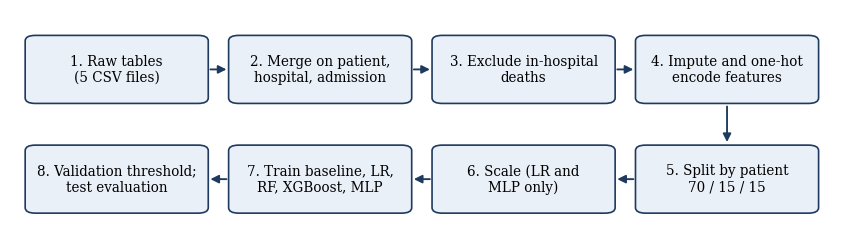

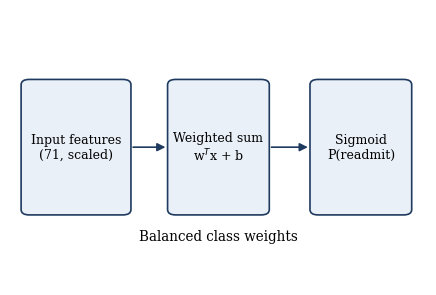

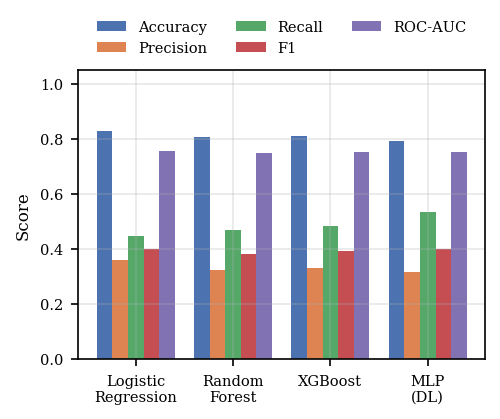

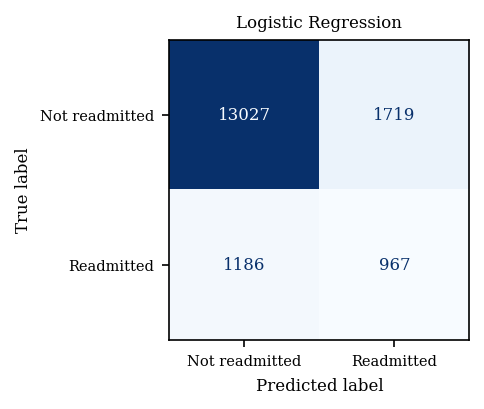

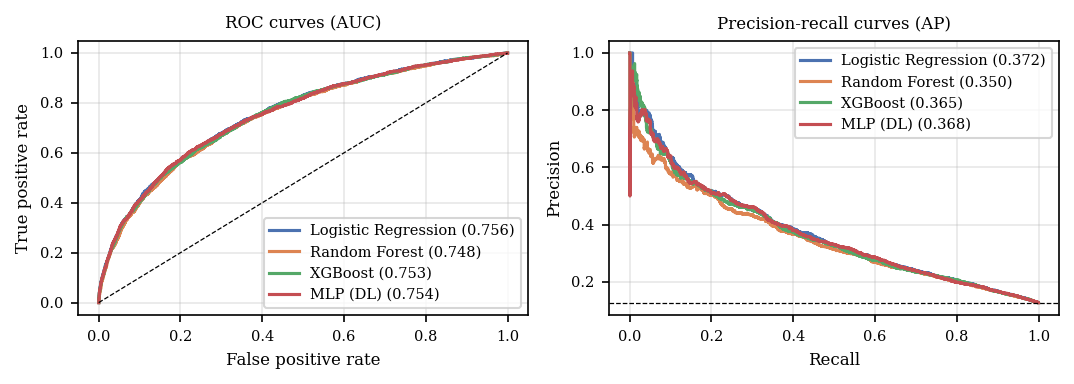

In [10]:
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay
V.flow_grid(["Raw tables\n(5 CSV files)", "Merge on patient,\nhospital, admission", "Exclude in-hospital\ndeaths",
             "Impute and one-hot\nencode features", "Split by patient\n70 / 15 / 15", "Scale (LR and\nMLP only)",
             "Train baseline, LR,\nRF, XGBoost, MLP", "Validation threshold;\ntest evaluation"], "fig1_workflow", ncols=4, w=7.0, h=1.9)
info = dict(n_features=X.shape[1])
if best == "Logistic Regression": pass
R["arch_info"] = info
V.architecture(best, info, "fig2_architecture")
names = learned; mets = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fig, ax = plt.subplots(figsize=(3.5, 2.5)); w = 0.16
for j, m in enumerate(mets):
    ax.bar(np.arange(len(names)) + (j - 2) * w, [res[n][m] for n in names], w, label="ROC-AUC" if m == "roc_auc" else ("F1" if m == "f1" else m.capitalize()), color=V.COLS[j])
ax.set_xticks(range(len(names))); ax.set_xticklabels([n.replace(" (DL)", "\n(DL)").replace(" ", "\n", 1) for n in names]); ax.set_ylim(0, 1.05)
ax.set_ylabel("Score"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.22), frameon=False); V.save(fig, "fig3_model_comparison")
fig, ax = plt.subplots(figsize=(3.0, 2.6))
cm = np.array([[res[best]["tn"], res[best]["fp"]], [res[best]["fn"], res[best]["tp"]]])
ConfusionMatrixDisplay(cm, display_labels=["Not readmitted", "Readmitted"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.grid(False); ax.set_title(best); V.save(fig, "fig4_confusion_matrix")
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.6))
for j, n in enumerate(learned):
    p_ = fitted[n][1]
    f, t_, _ = roc_curve(yte, p_); axs[0].plot(f, t_, color=V.COLS[j], label=f"{n} ({res[n]['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(yte, p_); axs[1].plot(rc, pr, color=V.COLS[j], label=f"{n} ({res[n]['pr_auc']:.3f})")
axs[0].plot([0, 1], [0, 1], "k--", lw=.6); axs[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (AUC)")
axs[1].axhline(yte.mean(), color="k", ls="--", lw=.6); axs[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (AP)")
axs[0].legend(loc="lower right"); axs[1].legend(loc="upper right"); fig.tight_layout(); V.save(fig, "fig5_roc_pr")
plt.show()

## 8. Save

In [11]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
import platform, sklearn, torch, xgboost
R["env"] = dict(python=platform.python_version(), sklearn=sklearn.__version__, torch=torch.__version__, xgboost=xgboost.__version__, seed=42)
R["features"] = list(X.columns)
# hyper-parameters actually used (read from the fitted objects, not typed by hand)
KEYS = ["C", "class_weight", "max_iter", "solver", "penalty", "n_estimators", "max_depth", "min_samples_leaf", "max_features", "learning_rate",
        "subsample", "colsample_bytree", "scale_pos_weight", "early_stopping_rounds", "eval_metric", "random_state"]
hp = {}
for n in learned:
    mdl = fitted[n][0]
    if n == "MLP (DL)":
        hp[n] = dict(hidden_layers=list(mdl.hidden), activation="ReLU", dropout=mdl.drop, optimizer="Adam", learning_rate=mdl.lr, batch_size=mdl.batch,
                     max_epochs=mdl.epochs, early_stopping_patience=mdl.patience, epochs_run=res[n].get("epochs_run"), loss="BCE with logits, pos_weight = neg/pos", seed=mdl.seed)
    else:
        hp[n] = {k: v for k, v in mdl.get_params().items() if k in KEYS}
        if n == "XGBoost": hp[n]["best_iteration"] = int(mdl.best_iteration) + 1
R["hyperparams"] = hp
R["colab"] = dict(in_colab=IN_COLAB, cpu_count=os.cpu_count())
json.dump(clean(R), open(f"{OUT}/results_v2.json", "w"), indent=2)
print("saved", f"{OUT}/results_v2.json", "| best:", best)

saved outputs_v2/results_v2.json | best: Logistic Regression


## 9. Summary block for the paper (take ONE screenshot of this cell's output)

In [12]:
print("=== ENVIRONMENT ===");  print(R["env"], R["colab"])
print("\n=== DATASET ===");    print(R["dataset"]); print(R["split"])
print("\n=== TEST-SET RESULTS ===")
print(pd.DataFrame(R["models"]).T[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier", "train_time_s", "predict_time_s"]].round(4))
print("\n=== ROC-AUC 95% CI ===");  print({k: [round(x, 4) for x in R["models"][k]["roc_auc_ci95"]] for k in learned})
print("\n=== DESIGN AUDIT ===");   print(pd.DataFrame(R["audit"]).T.round(4))
print("\n=== HYPERPARAMETERS ===")
for k, v in R["hyperparams"].items(): print(k, "->", v)
print("\nBest model:", R["best_model"], "| temporal AUC:", round(R["temporal"]["roc_auc"], 4))

=== ENVIRONMENT ===
{'python': '3.11.0', 'sklearn': '1.6.1', 'torch': '2.7.1+cpu', 'xgboost': '3.2.0', 'seed': 42} {'in_colab': False, 'cpu_count': 16}

=== DATASET ===
{'rows_raw': 120000, 'rows_used': 112587, 'dropped_expired': 7413, 'positives': 14210, 'rate': 0.1262135059998046, 'patients': 62923, 'n_features': 71, 'n_numeric': 21, 'n_categorical_raw': 9}
{'train': {'n': 78758, 'positives': 9873, 'rate': 0.12535869372000305}, 'val': {'n': 16930, 'positives': 2184, 'rate': 0.12900177200236268}, 'test': {'n': 16899, 'positives': 2153, 'rate': 0.12740398840168057}}

=== TEST-SET RESULTS ===
                     accuracy precision    recall        f1   roc_auc  \
Logistic Regression  0.828096  0.360015  0.449141  0.399669  0.755755   
Random Forest        0.808805  0.325792  0.468184   0.38422  0.748316   
XGBoost              0.810995  0.333333  0.483511  0.394617  0.752586   
MLP (DL)             0.794722  0.318633  0.536925  0.399931  0.754177   
Prior-only baseline  0.872596       

## 10. Download results (Colab only)

In [13]:
import shutil
if IN_COLAB:
    shutil.make_archive("outputs_v2_download", "zip", OUT)
    from google.colab import files
    files.download("outputs_v2_download.zip")
else:
    print("Not in Colab; results are in", OUT)

Not in Colab; results are in outputs_v2
